# DAgger 

## 1. Construct grid world

In [1]:
import torch
import json
from gridworld import GridWorld

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with open("gridworld.json", "r") as f:
    json_object = json.load(f)
    env = GridWorld(**json_object, device=device)

In [2]:
from IPython.display import HTML, display 

valid_states_all = torch.cat((env.valid_states, torch.tensor([env.grid_size-1,env.grid_size-1]).to(device).unsqueeze(dim=0)))

valid_states_all = valid_states_all[:,0]*env.grid_size + valid_states_all[:,1]

# print(valid_states_all)
# print(valid_states_all[:,0])
# print(valid_states_all[:,1])

html_text = "<table>" 
for row in range(env.grid_size):
    html_text += "<tr>"
    for col in range(env.grid_size):
        if row*env.grid_size + col in valid_states_all:
            html_text += "<td bgcolor=\"pearl\">"
        else:
            html_text += "<td>"
        html_text += str(env.reward_map[row*env.grid_size+col].tolist())
        html_text += "</td>"
    html_text += "</tr>"
html_text += "</table>"

display(HTML(html_text))

0,-1,0,0,0,-1,0,0,0,0,0,0,-1,0,-1,-1,-1,-1,0,-1,0,-1,0,0,0,-1,0,0,0,-1,-1,0,-1,0,0,0,0,-1,-1,0,0,0,0,0,0,0,0,0,0,0
-1,0,0,0,0,-1,0,-1,0,0,0,0,0,0,0,0,0,0,0,0,0,-1,-1,-1,0,-1,0,0,0,0,0,-1,0,-1,0,-1,0,-1,0,-1,-1,0,0,0,-1,-1,0,0,-1,-1
0,0,-1,-1,0,-1,0,-1,0,-1,0,0,0,0,0,0,0,-1,0,0,-1,0,0,-1,0,0,0,0,0,0,0,-1,0,0,-1,0,0,-1,-1,0,0,-1,0,0,0,0,-1,0,0,0
0,0,-1,0,-1,-1,0,0,-1,0,-1,0,0,0,0,-1,0,-1,0,-1,0,-1,0,0,-1,-1,0,0,-1,0,0,0,0,0,0,0,0,0,0,0,0,-1,0,0,0,0,0,0,0,-1
-1,-1,-1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1,-1,0,-1,0,0,0,0,0,0,0,0,0,0,0,0,-1,0,-1,0,0,0,-1,0,0,-1,0,-1,-1,0,0
0,-1,-1,0,0,-1,0,-1,0,0,-1,0,0,-1,0,0,-1,-1,0,0,-1,0,0,0,-1,0,0,0,0,-1,-1,0,0,-1,0,-1,-1,-1,-1,0,0,-1,0,-1,0,0,0,0,0,-1
-1,-1,0,0,0,0,0,0,0,0,0,0,-1,0,-1,0,0,0,0,0,-1,-1,0,0,-1,-1,0,0,-1,-1,0,-1,0,0,0,0,0,0,0,-1,-1,0,0,0,-1,0,-1,0,-1,-1
0,0,0,0,-1,0,0,0,-1,0,0,0,0,-1,0,0,-1,-1,0,0,-1,0,0,-1,0,0,-1,0,0,0,-1,-1,0,0,-1,0,-1,0,-1,0,0,-1,0,-1,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,-1,-1,0,-1,0,0,-1,0,0,-1,-1,0,0,0,0,0,0,-1,0,0,0,-1,-1,-1,-1,-1,-1,0,-1,-1,0,-1,0,0,0,-1,0,0,0,0
0,0,0,-1,0,-1,0,0,-1,-1,0,0,-1,0,0,0,0,0,0,0,0,0,-1,-1,-1,0,-1,0,0,0,0,0,0,0,0,0,0,-1,0,0,0,0,0,0,-1,-1,0,-1,-1,-1
0,0,0,0,0,-1,0,0,0,0,-1,0,0,-1,0,0,0,-1,0,0,0,-1,0,0,-1,0,0,0,-1,-1,0,-1,-1,0,0,0,0,0,-1,-1,-1,-1,-1,-1,0,0,-1,-1,-1,0


## 2. Define Policy

In [3]:
import torch.nn as nn
from torch.nn import functional as F

STATE_SIZE = env.grid_size*env.grid_size # 50 x 50 = 2500
ACTION_SIZE = env.action_size 

class ExpertNet(nn.Module):
    def __init__(self, hidden_dim=16):
        super().__init__()
        self.output = nn.Linear(STATE_SIZE, ACTION_SIZE, bias=False)

    def forward(self, state):
        logits = self.output(state)
        return logits

# Define policy for learner 
class LearnerNet(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.hidden = nn.Linear(STATE_SIZE, hidden_dim)
        self.classify = nn.Linear(hidden_dim, ACTION_SIZE)

    def forward(self, s):
        outs = self.hidden(s)
        outs = F.relu(outs)
        logits = self.classify(outs)
        return logits


In [4]:
# load expert model and freeze - no more update
expert_func = ExpertNet().to(device)
expert_func.load_state_dict(torch.load("expert_actor.pt"))
for param in expert_func.parameters():
    param.requires_grad = False 

# load learner model 
learner_func = LearnerNet().to(device)

In [5]:
# Pick stochastic samples with policy model
def pick_sample(policy, s):
    """
    Stochastically pick up action and logits with policy model.

    Parameters
    ----------
    policy : torch.nn.Module
        Policy network to use
    s : torch.tensor((..., STATE_SIZE), dtype=int)
        The feature (one-hot) of state.
        The above "..." can have arbitrary shape with 0 or 1 dimension.

    Returns
    ----------
    action : torch.tensor((...), dtype=int)
        The picked-up actions.
        If input shape is (*, STATE_SIZE), this shape becomes (*).
    """
    # get logits from state
    # --> size : (*, ACTION_SIZE)
    logits = policy(s.float())
    # from logits to probabilities
    # --> size : (*, ACTION_SIZE)
    probs = F.softmax(logits, dim=-1)
    # pick up action's sample
    # --> size : (*, 1)
    a = torch.multinomial(probs, num_samples=1)
    # --> size : (*)
    a = a.squeeze()

    # Return
    return a

In [6]:
def evaluate(policy, batch_size):
    total_reward = torch.tensor(0.0).to(device)
    s = env.reset(batch_size)
    while True:
        s_onehot = F.one_hot(s, num_classes=STATE_SIZE)
        with torch.no_grad():
            a = pick_sample(policy, s_onehot)
        s, r, term, trunc = env.step(a, s)
        total_reward += torch.sum(r)
        done = torch.logical_or(term, trunc)
        work_indices = (done==False).nonzero().squeeze(dim=-1)
        if not (len(work_indices) > 0):
            break;
        s = s[work_indices]
    return total_reward.item() / batch_size

In [7]:
avg_reward = evaluate(learner_func, 300)
print(f"Estimated rewards (before training): {avg_reward}")

Estimated rewards (before training): -68.50666666666666


### get $\beta$

In [8]:
def get_beta(p, iter_num):
    return p**iter_num

In [9]:
import random 

def collect_states(expert, learner, p_for_beta, i, collect_dat):
    collected_states = [] 
    beta = get_beta(p_for_beta, i)
    done = True 
    while len(collected_states) < collect_dat:
        if done:
            s = env.reset(batch_size=1)
            done = False 

        collected_states.append(s.squeeze(dim=0))
        s_onehot = F.one_hot(s.squeeze(dim=0), num_classes=STATE_SIZE)
        
        # collected_states.append(s_onehot)
        rnd = random.uniform(0, 1)
        policy = expert if rnd < beta else learner 
        with torch.no_grad():
            a = pick_sample(policy, s_onehot)

        s, _, term, trunc = env.step(a.unsqueeze(dim=0), s)
        done = torch.logical_or(term, trunc).squeeze(dim=0)

    return torch.stack(collected_states, dim=0)

In [10]:
def train(expert, learner, p_for_beta, collect_dat, total_aggregate, train_batch_size, verbose=False):
    reward_log = []
    # 1D tensors storing scalar state IDs and action IDs
    visited_states_all = torch.empty((0,), dtype=torch.int64).to(device)
    expert_actions_all = torch.empty((0,), dtype=torch.int64).to(device) 

    opt = torch.optim.AdamW(learner.parameters(), lr=0.001)

    for i in range(total_aggregate):
        # 1. Collect visited states as scalar IDs (shape: [collect_dat])
        visited_states = collect_states(expert, learner, p_for_beta, i, collect_dat)
        
        # 2. Query expert (convert only this iteration's states to one-hot for the expert)
        with torch.no_grad():
            visited_onehot = F.one_hot(visited_states, num_classes=STATE_SIZE).float()
            logits = expert(visited_onehot)
            probs = F.softmax(logits, dim=-1)
            expert_actions = torch.multinomial(probs, num_samples=1).squeeze(dim=-1)
        
        # 3. Aggregate datasets (each is just 1D integers)
        visited_states_all = torch.cat((visited_states_all, visited_states), dim=0)
        expert_actions_all = torch.cat((expert_actions_all, expert_actions), dim=0)

        # 4. Shuffle indices (does NOT duplicate the data!)
        indices = torch.randperm(visited_states_all.shape[0], device=device)

        # 5. Train learner by chunking mini-batches
        total_samples = visited_states_all.shape[0]
        for j in range(0, total_samples, train_batch_size):
            batch_idx = indices[j : j + train_batch_size]
            batch_s = visited_states_all[batch_idx]
            batch_a = expert_actions_all[batch_idx]

            # Convert ONLY the 200 mini-batch states to one-hot on the fly (~2 MB VRAM)
            batch_s_onehot = F.one_hot(batch_s, num_classes=STATE_SIZE).float()

            opt.zero_grad()
            logits = learner(batch_s_onehot)
            loss = F.cross_entropy(logits, batch_a)
            loss.backward()
            opt.step()

        # 6. Evaluate policy
        avg = evaluate(learner, 200)
        reward_log.append(avg)
        if verbose:
            print("Iteration {:2d} - Evaluation result (Average reward): {:.2f}".format(i + 1, avg))

    return reward_log

In [11]:
# def train(expert, learner, p_for_beta, collect_dat, total_aggregate, train_batch_size, verbose=False):
#     """
#     Train with DAgger

#     Parameters
#     ----------
#     expert: torch.nn.Module 
#             Online expert policy
#     learner: torch.nn.Module 
#             Learner policy
#     p_for_beta: int 
#                 Base p value used in get_beta() function
#     collect_dat: int 
#                 The number of data to collect in each data aggregation
#     total_aggregate: int
#                     The number of aggregation
#                     As a result, the number of total collected data will be collect_dat * total_aggregate.
#     train_batch_size: int 
#                     The number of data in each training batch.
#                     The collected data is divided into this chunk as a batch, and each batch is then trained.
#     verbose: bool
#             Whether to print results or not

#     Returns
#     -------
#     logs: int[total_aggregate]
#         Returns the results of evaluated rewards in each aggregation
#     """

#     reward_log = []
#     visited_states_all = torch.empty((0, STATE_SIZE), dtype=torch.int64).to(device)
#     expert_actions_all = torch.empty((0), dtype=torch.int64).to(device) 

#     # create optimizer
#     opt = torch.optim.AdamW(learner.parameters(), lr=0.001)

#     for i in range(total_aggregate):
#         # collect visited states (onehot)
#         visited_states = collect_states(expert, learner, p_for_beta, i, collect_dat)
#         # collect expert actions
#         with torch.no_grad():
#             logits = expert(visited_states.float())

#         probs = F.softmax(logits, dim=-1)
#         expert_actions = torch.multinomial(probs, num_samples=1)
#         expert_actions = expert_actions.squeeze(dim=-1)
        
#         # combine dataset
#         visited_states_all = torch.cat((visited_states_all, visited_states), dim=0)
#         expert_actions_all = torch.cat((expert_actions_all, expert_actions), dim=0)

#         # shuffle dataset for training
#         indices = torch.randperm(visited_states_all.shape[0])
#         visited_states_train = visited_states_all[indices]
#         expert_actions_train = expert_actions_all[indices]

#         # train learner policy by chunking dataset
#         for j in range(0, collect_dat, train_batch_size):
#             opt.zero_grad()
#             logits = learner(visited_states_train[j:j+train_batch_size].float())
#             loss = F.cross_entropy(logits, expert_actions_train[j:j+train_batch_size], reduction="none")
#             loss.sum().backward()
#             opt.step()

#         # evaluate policy and log
#         avg = evaluate(learner, 200)
#         reward_log.append(avg)
#         if verbose:
#             print("Iteration {:2d} - Evaluation result (Average reward) {}".format(i + 1, avg))

#     return reward_log 



In [12]:
dagger_results = train(
    expert=expert_func,
    learner=learner_func,
    p_for_beta=0.3,
    collect_dat=5000,
    total_aggregate=30,
    train_batch_size=300,
    verbose=True,
)

Iteration  1 - Evaluation result (Average reward): -67.10
Iteration  2 - Evaluation result (Average reward): -65.46
Iteration  3 - Evaluation result (Average reward): -38.55
Iteration  4 - Evaluation result (Average reward): -15.37
Iteration  5 - Evaluation result (Average reward): -1.07
Iteration  6 - Evaluation result (Average reward): 5.11
Iteration  7 - Evaluation result (Average reward): 7.58
Iteration  8 - Evaluation result (Average reward): 7.75
Iteration  9 - Evaluation result (Average reward): 8.74
Iteration 10 - Evaluation result (Average reward): 8.48
Iteration 11 - Evaluation result (Average reward): 8.50
Iteration 12 - Evaluation result (Average reward): 8.46
Iteration 13 - Evaluation result (Average reward): 8.29
Iteration 14 - Evaluation result (Average reward): 8.71
Iteration 15 - Evaluation result (Average reward): 8.02
Iteration 16 - Evaluation result (Average reward): 8.85
Iteration 17 - Evaluation result (Average reward): 8.59
Iteration 18 - Evaluation result (Avera

Iteration  1 - Evaluation result (Average reward): -66.03
Iteration  2 - Evaluation result (Average reward): -65.33
Iteration  3 - Evaluation result (Average reward): -40.13
Iteration  4 - Evaluation result (Average reward): -24.09
Iteration  5 - Evaluation result (Average reward): -11.69
Iteration  6 - Evaluation result (Average reward): -0.64
Iteration  7 - Evaluation result (Average reward): 1.53
Iteration  8 - Evaluation result (Average reward): 4.50
Iteration  9 - Evaluation result (Average reward): 5.54
Iteration 10 - Evaluation result (Average reward): 6.34
Iteration 11 - Evaluation result (Average reward): 7.31
Iteration 12 - Evaluation result (Average reward): 7.23
Iteration 13 - Evaluation result (Average reward): 7.96
Iteration 14 - Evaluation result (Average reward): 7.90
Iteration 15 - Evaluation result (Average reward): 7.72
Iteration 16 - Evaluation result (Average reward): 7.67
Iteration 17 - Evaluation result (Average reward): 8.44
Iteration 18 - Evaluation result (Ave

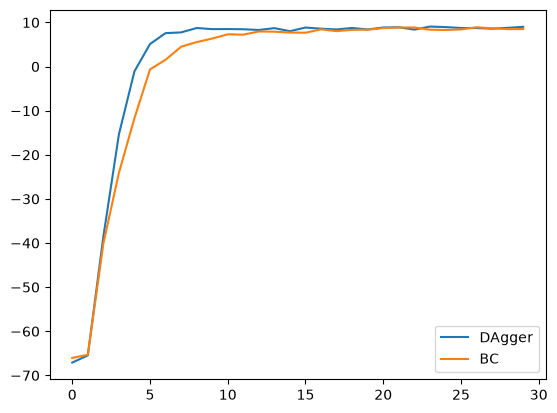

In [13]:
import matplotlib.pyplot as plt

# train with behavior cloning (BC)
# (by setting p_for_beta=1.0)
bc_learner_func = LearnerNet().to(device)
bc_results = train(
    expert=expert_func,
    learner=bc_learner_func,
    p_for_beta=1.0,
    collect_dat=5000,
    total_aggregate=30,
    train_batch_size=300,
    verbose=True
)

# plot
plt.plot(dagger_results, label="DAgger")
plt.plot(bc_results, label="BC")
plt.legend()
plt.show()
